# 👁️ Eye State CNN — Baseline (Synapse)

**الهدف:** نموذج CNN مبني من الصفر بيصنّف صورة العين: **مغلقة (0)** أو **مفتوحة (1)**.

| | |
|---|---|
| **الداتا** | MRL Eye Dataset — splits جاهزة من Member 1 (مقسّمة حسب الشخص) |
| **المدخل** | صورة رمادية 64×64×1، قيمها بين 0 و 1 |
| **المخرج** | احتمال إن العين **مفتوحة** (sigmoid) |
| **الملفات الناتجة** | الأوزان، منحنيات التدريب، Confusion Matrix، تقرير الدقة |

> هاد هو الـ **baseline**: أول نموذج بسيط بنقيس عليه. بعده بنجرب MobileNetV2 + Fine-tuning ونقارن.

## 1) تجهيز البيئة
- **ليش بنعمل clone للريبو؟** عشان نستخدم نفس الـ `make_dataset` يلي كتبته منار، فالمعالجة تكون **نفسها بالضبط** بين التدريب والـ real-time.
- **ليش `set_random_seed(42)`؟** عشان لو أعدنا التشغيل نطلع بنتائج قريبة جداً (reproducibility) — مهم للتقرير.

In [1]:
import os, sys, json
if not os.path.exists("Synapse"):
    !git clone -q https://github.com/ManarAbu-Irsheid/Synapse.git
sys.path.insert(0, "Synapse/data_pipeline")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from dataset import make_dataset          # loader تبع Member 1

tf.keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2) الإعدادات (Hyperparameters)
كل الأرقام يلي ممكن نغيّرها بمكان واحد، عشان التجارب تكون منظمة.
- `IMG_SIZE = 64` لأنه هيك بيطلع الـ loader وهيك بيعالج `preprocess_eye` بالـ real-time.
- `LR = 1e-3` قيمة البداية المعروفة لـ Adam.
- `EPOCHS = 30` حد أعلى بس — الـ EarlyStopping غالباً بيوقف قبل.

In [2]:
SPLITS   = "Synapse/data_pipeline/splits"
OUT      = "/kaggle/working/eye_cnn_baseline"
IMG_SIZE = 64
BATCH    = 64
EPOCHS   = 30
LR       = 1e-3
CLASS_NAMES = ["closed", "open"]          # 0 = closed, 1 = open
os.makedirs(OUT, exist_ok=True)

## 3) فحص الداتا قبل التدريب
- **ليش؟** لو المسارات غلط أو الفئات مش متوازنة، بنكتشف هلأ مش بعد ساعة تدريب.
- لو الفئات **متوازنة** (قريبة من 50/50) ما بنحتاج `class_weight`.
- **مهم:** ملف الـ train مرتّب حسب الفئة، فبنخلطه كامل قبل التدريب. بدون هالخطوة، كل batch بتكون من فئة وحدة تقريباً، والـ BatchNorm بيتعلم إحصائيات غلط، والنموذج بيصير يتنبأ بفئة وحدة بس على الـ val/test (هاد يلي صار بأول تجربة: accuracy = 47%).

In [3]:
dfs = {s: pd.read_csv(f"{SPLITS}/mrl_{s}.csv") for s in ["train", "val", "test"]}
for s, d in dfs.items():
    counts = d.label.value_counts().sort_index()
    print(f"{s:5s}: {len(d):6d} images | subjects={d.subject.nunique():2d} | "
          f"closed={counts[0]} ({counts[0]/len(d):.0%}) open={counts[1]}")

# تأكد إن الصور موجودة فعلاً على Kaggle
missing = [p for p in dfs["train"].path.head(20) if not os.path.exists(p)]
assert not missing, f"المسارات مش موجودة! تأكدي إنك ضايفة MRL Eye Dataset كـ Input. مثال: {missing[0]}"
print("✅ المسارات سليمة")

train:  55330 images | subjects=25 | closed=26705 (48%) open=28625
val  :  23502 images | subjects= 6 | closed=12019 (51%) open=11483
test :   6066 images | subjects= 6 | closed=3222 (53%) open=2844
✅ المسارات سليمة


نسبة open بأول 10 batches بعد الخلط: [0.5  0.56 0.41 0.66 0.56 0.58 0.45 0.48 0.52 0.47]


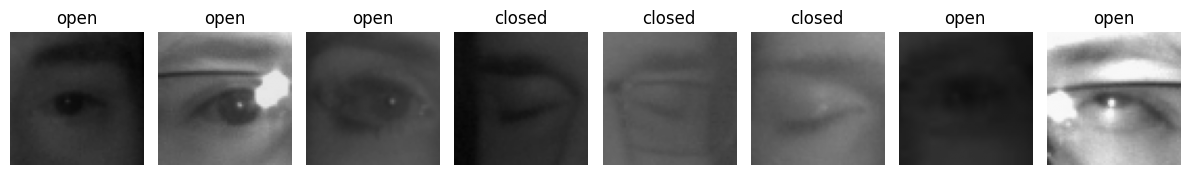

batch shape: (64, 64, 64, 1) | min/max: 0.0 1.0


In [4]:
# ⚠️ إصلاح: ملف mrl_train.csv مرتّب (كل الـ closed أول، بعدين كل الـ open)، والـ shuffle buffer
# بالـ loader (10,000) أصغر من الداتا (55,330) ← الـ batches بتطلع من فئة وحدة تقريباً
# وهاد بيخرب الـ BatchNorm. الحل: نخلط الملف كامل مرة وحدة قبل ما نعطيه للـ loader.
os.makedirs("/kaggle/working/splits_shuffled", exist_ok=True)
TRAIN_CSV = "/kaggle/working/splits_shuffled/mrl_train.csv"
dfs["train"].sample(frac=1, random_state=42).to_csv(TRAIN_CSV, index=False)
lab = pd.read_csv(TRAIN_CSV).label.values
n = min(10, len(lab) // BATCH)
first = lab[:n * BATCH].reshape(n, BATCH).mean(1)
print(f"نسبة open بأول {n} batches بعد الخلط:", first.round(2))   # لازم تكون قريبة من 0.5

train_ds = make_dataset(TRAIN_CSV, training=True,  batch_size=BATCH, size=IMG_SIZE)
val_ds   = make_dataset(f"{SPLITS}/mrl_val.csv",   training=False, batch_size=BATCH, size=IMG_SIZE)
test_ds  = make_dataset(f"{SPLITS}/mrl_test.csv",  training=False, batch_size=BATCH, size=IMG_SIZE)

# نظرة على عينة من صور التدريب (بعد الـ augmentation)
imgs, labels = next(iter(train_ds))
plt.figure(figsize=(12, 3))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(imgs[i, ..., 0], cmap="gray", vmin=0, vmax=1)
    plt.title(CLASS_NAMES[int(labels[i])]); plt.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/samples.png", dpi=120); plt.show()
print("batch shape:", imgs.shape, "| min/max:", float(tf.reduce_min(imgs)), float(tf.reduce_max(imgs)))

## 4) بناء النموذج
**المعمارية:** 3 بلوكات، كل بلوك:
`Conv → BatchNorm → ReLU → Conv → BatchNorm → ReLU → MaxPool → Dropout`

| الطبقة | ليش؟ |
|---|---|
| **Conv2D (3×3)** | بتطلع features: حواف ← أشكال (الجفن، البؤبؤ) |
| **فلاتر 32 ← 64 ← 128** | كل ما نتعمق الصورة بتصغر، فبنزيد الفلاتر لنمسك تفاصيل أعقد |
| **BatchNormalization** | بتثبّت التدريب وبتسرّعه |
| **MaxPooling** | بتصغّر الحجم للنص وبتخلي النموذج أقل حساسية لمكان العين بالضبط |
| **Dropout** | بتطفي neurons عشوائياً أثناء التدريب ← **ضد الـ Overfitting** |
| **L2 regularization** | بتعاقب الأوزان الكبيرة ← **ضد الـ Overfitting** |
| **GlobalAveragePooling** | بدل Flatten: parameters أقل بكثير ← overfitting أقل |
| **Dense(1, sigmoid)** | احتمال واحد بين 0 و 1 لأنه تصنيف ثنائي |

In [5]:
def conv_block(x, filters, drop):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                          kernel_regularizer=regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(drop)(x)

def build_eye_cnn(img_size=IMG_SIZE):
    inp = keras.Input((img_size, img_size, 1), name="eye_gray")
    x = conv_block(inp, 32, 0.20)     # 64 -> 32
    x = conv_block(x,   64, 0.25)     # 32 -> 16
    x = conv_block(x,  128, 0.30)     # 16 -> 8
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(1, activation="sigmoid", name="p_open")(x)
    return keras.Model(inp, out, name="eye_cnn_baseline")

model = build_eye_cnn()
model.summary()

Model: "eye_cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ eye_gray (InputLayer)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 304,417 (1.16 MB)

 Trainable params: 303,521 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

## 5) التدريب
- **Optimizer = Adam:** بيعدّل الـ learning rate لكل وزن لحاله — أفضل نقطة بداية.
- **Loss = binary_crossentropy:** المناسبة لتصنيف ثنائي مع sigmoid.
- **Metrics:** accuracy + precision + recall + AUC (الـ accuracy لحالها ما بتكفي).

**الـ Callbacks:**
| Callback | ليش؟ |
|---|---|
| `EarlyStopping` | بيوقف لما الـ val_loss يبطّل يتحسن 5 epochs ← **ضد الـ Overfitting** + بيرجّع أفضل أوزان |
| `ReduceLROnPlateau` | بيقسم الـ LR على 2 لما التحسن يوقف ← خطوات أدق قرب الحل |
| `ModelCheckpoint` | بيحفظ أفضل نموذج أول بأول — لو انقطع الـ session ما بنخسر |
| `CSVLogger` | بيحفظ أرقام كل epoch للتقرير |

In [6]:
model.compile(
    optimizer=keras.optimizers.Adam(LR),
    loss="binary_crossentropy",
    metrics=["accuracy",
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall"),
             keras.metrics.AUC(name="auc")],
)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint(f"{OUT}/best.keras", monitor="val_loss", save_best_only=True),
    keras.callbacks.CSVLogger(f"{OUT}/history.csv"),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)

Epoch 1/30


E0000 00:00:1795165737.406791      78 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


864/865 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.6955 - auc: 0.7690 - loss: 0.5803 - precision: 0.7404 - recall: 0.6291

E0000 00:00:1795166706.008549      78 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


865/865 ━━━━━━━━━━━━━━━━━━━━ 1463s 2s/step - accuracy: 0.8188 - auc: 0.9166 - loss: 0.3959 - precision: 0.8561 - recall: 0.7809 - val_accuracy: 0.8984 - val_auc: 0.9831 - val_loss: 0.3610 - val_precision: 0.9984 - val_recall: 0.7934 - learning_rate: 0.0010
Epoch 2/30
865/865 ━━━━━━━━━━━━━━━━━━━━ 30s 35ms/step - accuracy: 0.9721 - auc: 0.9953 - loss: 0.1231 - precision: 0.9740 - recall: 0.9720 - val_accuracy: 0.7110 - val_auc: 0.9740 - val_loss: 0.7251 - val_precision: 0.6286 - val_recall: 0.9980 - learning_rate: 0.0010
Epoch 3/30
865/865 ━━━━━━━━━━━━━━━━━━━━ 30s 35ms/step - accuracy: 0.9776 - auc: 0.9968 - loss: 0.1023 - precision: 0.9775 - recall: 0.9793 - val_accuracy: 0.9346 - val_auc: 0.9933 - val_loss: 0.1750 - val_precision: 0.8931 - val_recall: 0.9840 - learning_rate: 0.0010
Epoch 4/30
865/865 ━━━━━━━━━━━━━━━━━━━━ 30s 35ms/step - accuracy: 0.9791 - auc: 0.9971 - loss: 0.0965 - precision: 0.9788 - recall: 0.9808 - val_accuracy: 0.9629 - val_auc: 0.9922 - val_loss: 0.1473 - val_pr

## 6) منحنيات التدريب
**كيف نقرأها؟**
- train و val **ماشيين مع بعض** ← ممتاز.
- train بيتحسن و val **بيسوء** ← Overfitting.
- الاثنين سيئين ← Underfitting (النموذج بسيط زيادة أو التدريب قصير).

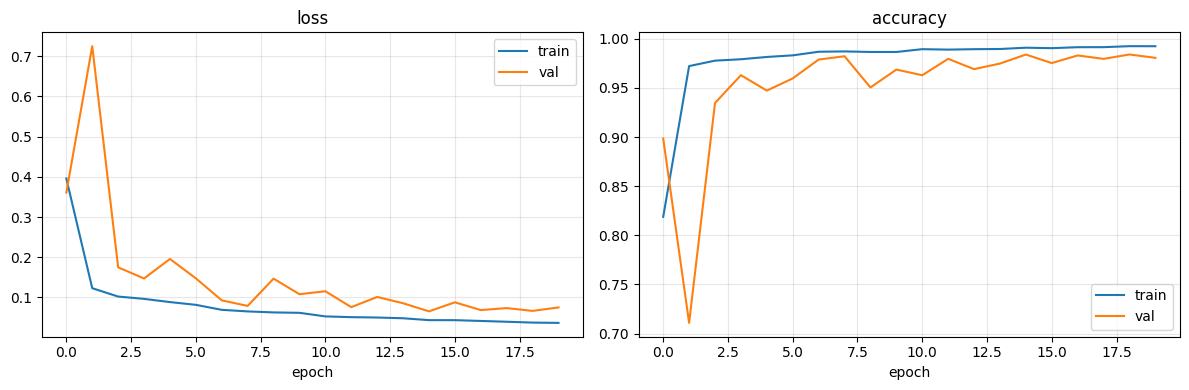

In [7]:
h = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, m in enumerate(["loss", "accuracy"]):
    ax[i].plot(h[m], label="train"); ax[i].plot(h[f"val_{m}"], label="val")
    ax[i].set_title(m); ax[i].set_xlabel("epoch"); ax[i].legend(); ax[i].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/training_curves.png", dpi=120); plt.show()

## 7) التقييم على الـ Test Set
- الـ test set **ما شافه النموذج أبداً** (ولا حتى أشخاصه)، فهو أصدق مقياس.
- **أهم رقم لمشروعنا: Recall لفئة closed** — يعني من كل العيون المسكّرة فعلاً، كم وحدة كشفها النموذج؟ تفويت عين مسكّرة = تفويت نعاس.

              precision    recall  f1-score   support

      closed     0.9910    0.9609    0.9757      3222
        open     0.9572    0.9902    0.9734      2844

    accuracy                         0.9746      6066
   macro avg     0.9741    0.9755    0.9746      6066
weighted avg     0.9752    0.9746    0.9746      6066



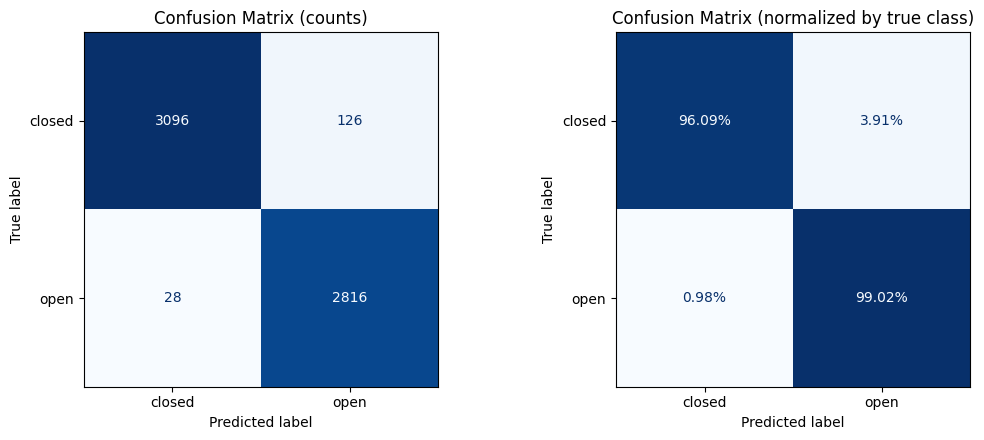

In [8]:
y_true = dfs["test"].label.values                 # الترتيب محفوظ لأنه test_ds مش shuffled
y_prob = model.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, output_dict=True)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion Matrix (counts)")
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, normalize="true"),
                       display_labels=CLASS_NAMES).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".2%")
ax[1].set_title("Confusion Matrix (normalized by true class)")
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrix.png", dpi=120); plt.show()

## 8) حفظ النموذج والنتائج
- `eye_cnn_baseline.keras`: النموذج كامل (معمارية + أوزان) — هاد يلي بيستخدمه باقي الفريق.
- `eye_cnn_baseline.weights.h5`: الأوزان لحالها (مطلوبة بالمهمة).
- `metrics.json`: كل الأرقام بمكان واحد للتقرير ولمقارنة النماذج الجاية.

In [9]:
model.save(f"{OUT}/eye_cnn_baseline.keras")
model.save_weights(f"{OUT}/eye_cnn_baseline.weights.h5")

test_eval = model.evaluate(test_ds, verbose=0, return_dict=True)
metrics = {
    "model": "eye_cnn_baseline",
    "params": int(model.count_params()),
    "epochs_trained": len(h),
    "best_val_loss": float(h.val_loss.min()),
    "test_accuracy": report["accuracy"],
    "test_auc": float(test_eval["auc"]),
    "closed": {k: report["closed"][k] for k in ["precision", "recall", "f1-score", "support"]},
    "open":   {k: report["open"][k]   for k in ["precision", "recall", "f1-score", "support"]},
    "confusion_matrix": cm.tolist(),
    "hyperparameters": {"img_size": IMG_SIZE, "batch": BATCH, "lr": LR, "max_epochs": EPOCHS},
}
json.dump(metrics, open(f"{OUT}/metrics.json", "w"), indent=2)
print(json.dumps(metrics, indent=2))
print("\nFiles:", sorted(os.listdir(OUT)))

{
  "model": "eye_cnn_baseline",
  "params": 304417,
  "epochs_trained": 20,
  "best_val_loss": 0.06553022563457489,
  "test_accuracy": 0.9746125947906363,
  "test_auc": 0.9966996908187866,
  "closed": {
    "precision": 0.9910371318822023,
    "recall": 0.9608938547486033,
    "f1-score": 0.9757327450362433,
    "support": 3222.0
  },
  "open": {
    "precision": 0.9571719918422842,
    "recall": 0.9901547116736991,
    "f1-score": 0.973384030418251,
    "support": 2844.0
  },
  "confusion_matrix": [
    [
      3096,
      126
    ],
    [
      28,
      2816
    ]
  ],
  "hyperparameters": {
    "img_size": 64,
    "batch": 64,
    "lr": 0.001,
    "max_epochs": 30
  }
}

Files: ['best.keras', 'confusion_matrix.png', 'eye_cnn_baseline.keras', 'eye_cnn_baseline.weights.h5', 'history.csv', 'metrics.json', 'samples.png', 'training_curves.png']


## 9) استخدام النموذج بالـ real-time (للفريق)
```python
from tensorflow import keras
from face_utils import preprocess_eye
model = keras.models.load_model("eye_cnn_baseline.keras")
x = preprocess_eye(eye_roi_bgr)            # (64, 64, 1)
p_open = model.predict(x[None], verbose=0)[0, 0]
eye_closed = p_open < 0.5
```
**الخطوة الجاية:** MobileNetV2 + Fine-tuning ومقارنة نتائجه مع هاد الـ baseline.